In [1]:
# Linear Regression

In [2]:
# Step 1: Import libraries

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [4]:
# Step 2: Load dataset

In [5]:

df = pd.read_csv("cybersecurity_regression_dataset.csv")

print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())


      traffic  packet_size  connections    latency
0  844.327631   572.023901           50  81.382959
1  407.046769   575.175261           45  51.087764
2  934.408999   637.236279           50  82.157486
3  854.848353   263.480506           59  74.089199
4  280.539247   580.274852           60  62.119639

Dataset Shape: (10000, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   traffic      10000 non-null  float64
 1   packet_size  10000 non-null  float64
 2   connections  10000 non-null  int64  
 3   latency      10000 non-null  float64
dtypes: float64(3), int64(1)
memory usage: 312.6 KB
None

Missing Values:
traffic        0
packet_size    0
connections    0
latency        0
dtype: int64

Duplicate Records: 0

Statistical Summary:
            traffic   packet_size   connections       latency
count  10000.000000  1000

In [6]:
# Step 3: Exploratory Data Analysis (EDA)

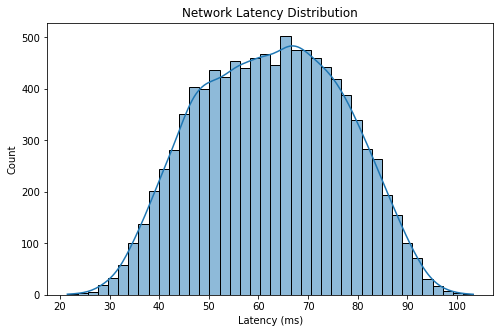

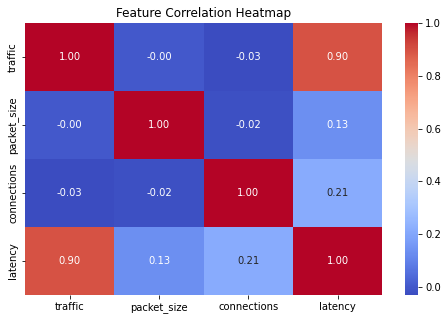

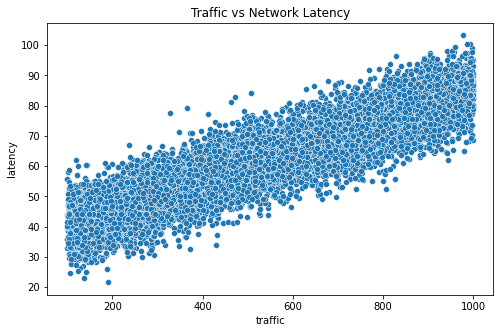

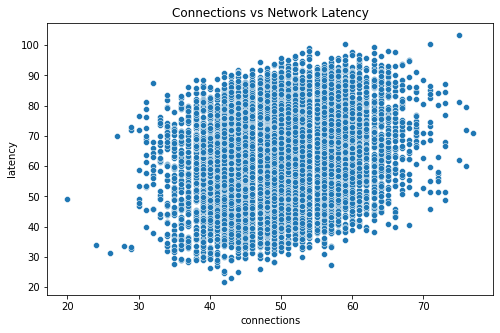

In [7]:

# Distribution of network latency
plt.figure(figsize=(8, 5))
sns.histplot(df["latency"], kde=True)
plt.title("Network Latency Distribution")
plt.xlabel("Latency (ms)")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()

# Traffic vs latency
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="traffic", y="latency")
plt.title("Traffic vs Network Latency")
plt.show()

# Connections vs latency
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="connections", y="latency")
plt.title("Connections vs Network Latency")
plt.show()


In [8]:
# Step 4: Define input features (X) and target (Y)

In [9]:

# Input features
X = df[["traffic", "packet_size", "connections"]]

# Target variable
y = df["latency"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Features:
      traffic  packet_size  connections
0  844.327631   572.023901           50
1  407.046769   575.175261           45
2  934.408999   637.236279           50
3  854.848353   263.480506           59
4  280.539247   580.274852           60

Target Variable:
0    81.382959
1    51.087764
2    82.157486
3    74.089199
4    62.119639
Name: latency, dtype: float64


In [10]:
# Step 5: Split the dataset

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (8000, 3)
Testing Data: (2000, 3)


In [12]:
# Step 6: Build and train Linear Regression model

In [13]:

model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Train model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [14]:
# Step 7: Make predictions

In [15]:

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Latency": y_test.values,
    "Predicted Latency": y_pred
})

print(results.head(10))


   Actual Latency  Predicted Latency
0       60.893135          61.136405
1       68.502636          65.429936
2       53.520221          45.501405
3       77.554508          75.587016
4       66.848702          73.282360
5       65.265225          63.838468
6       81.215392          85.233603
7       68.662418          70.767238
8       72.871938          75.426295
9       78.487507          76.271021


In [16]:
# Step 8: Evaluate the model

In [17]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Model Evaluation Results
-------------------------
MAE: 3.949248279770975
MSE: 24.47753116879965
RMSE: 4.9474772529845605
R2 Score: 0.8839895755554704


In [18]:
# Step 9: Actual vs predicted visualization

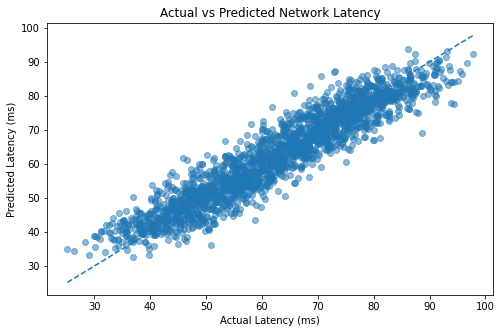

In [19]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Latency (ms)")
plt.ylabel("Predicted Latency (ms)")
plt.title("Actual vs Predicted Network Latency")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()


In [20]:
# Step 10: Feature coefficient interpretation

In [21]:

regressor = model.named_steps["regressor"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regressor.coef_
})

print("Feature Coefficients:")
print(coefficients)

print("\nIntercept:", regressor.intercept_)


Feature Coefficients:
       Feature  Coefficient
0      traffic    12.918515
1  packet_size     2.004326
2  connections     3.552957

Intercept: 62.543075064368004


In [22]:
# Step 11: Predict latency for a new network scenario

In [23]:

new_network = pd.DataFrame({
    "traffic": [850],
    "packet_size": [600],
    "connections": [50]
})

predicted_latency = model.predict(new_network)

print(
    "Predicted Network Latency:",
    round(predicted_latency[0], 2),
    "ms"
)


Predicted Network Latency: 79.47 ms
